# gifs.py

*Generated from `gifs.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
gifs.py -- illustrative animations of the workflow (values are NOT real).

    python3 gifs.py            # -> ../gifs/G1..G4 .gif  (about 1 min to render)
    python3 gifs.py G2         # just one

G1_workflow        the pipeline stage by stage, with a cartoon of what each does
G2_search          energy-landscape picture of one cluster's search: CG, then
                   300 / 614.6 / 900 K anneals, quench, CG; lowest minimum kept
G3_vacancy_filling He added one at a time to a W vacancy in WC; binding energy
                   drops and the last He escapes to a channel (capacity)
G4_jw_vacancy_rule how Juslin & Wirth grow vacancy clusters in bcc W: remove
                   the highest-energy W atom next to the void (ties -> lowest ID)
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'gifs.py'
ARGS = []              # all four; or e.g. ["G2"]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import os
import sys
import numpy as np
from style import *  # noqa
from matplotlib.patches import Rectangle

In [3]:
OUT = os.path.join(os.path.dirname(os.path.abspath(__file__)), "..", "gifs")
os.makedirs(OUT, exist_ok=True)
DPI = 90


def smooth(u):
    u = min(max(u, 0.0), 1.0)
    return u * u * (3 - 2 * u)

In [4]:
# ===================================================================== G1
STAGES = [
    ("in.bulk0", "relax the WC box at 0 K", "proc"),
    ("in.ref", "one He at the channel site", "proc"),
    ("make_v3.py", "clusters + random He", "in"),
    ("in.<series>", "CG → anneal ×3 → CG", "proc"),
    ("analyze_v3.py", "lowest intact minimum,\nbinding energies, flags", "ana"),
    ("plot_v3.py", "figures", "out"),
]


R = (0.70 * 9.6) / (0.55 * 5.0)     # data aspect of the stage panel (x range when y is 0..1)


def mini_lattice(ax, scale=1.0, vac=(), he=(), cx=R / 2, cy=0.47, n=6, sp=0.17):
    """Small WC patch in panel data units (aspect is 1:1)."""
    for i in range(n):
        for j in range(3):
            x = cx + (i - (n - 1) / 2) * sp * scale
            y = cy + (j - 1) * sp * 0.97 * scale
            if (i, j) in vac:
                ax.add_patch(Circle((x, y), 0.05, fc="none", ec=VAC_C, lw=1.6, ls=(0, (2, 1))))
            else:
                ax.add_patch(Circle((x, y), 0.05, fc=W_C, ec=W_EDGE, lw=0.6))
            if i < n - 1 and j < 2:
                ax.add_patch(Circle((x + sp * scale / 2, y + sp * 0.485 * scale), 0.03, fc=C_C,
                                    ec=C_EDGE, lw=0.4))
    for (x, y) in he:
        ax.add_patch(Circle((x, y), 0.036, fc=HE_C, ec=HE_EDGE, lw=0.6, zorder=5))


def g1():
    frames = []
    per = 22
    rng = np.random.default_rng(4)
    he_rand = rng.uniform(-0.03, 0.03, size=(4, 2))
    for st in range(len(STAGES)):
        for f in range(per):
            u = f / (per - 1)
            fig = plt.figure(figsize=(9.6, 5.0))
            ax = fig.add_axes([0, 0, 1, 1])
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.axis("off")
            ax.text(0.5, 0.94, "He in WC workflow (v3)", ha="center", fontsize=15, weight="bold")
            bw, gap = 0.142, 0.02
            for k, (t, d, kind) in enumerate(STAGES):
                x = 0.025 + k * (bw + gap)
                on = k == st
                done = k < st
                box(ax, x, 0.70, bw, 0.13, "", kind, lw=2.6 if on else 1.0,
                    alpha=1.0 if (on or done) else 0.35, pad=0.004)
                ax.text(x + bw / 2, 0.79, t, ha="center", fontsize=9.5, weight="bold",
                        color=EDGE[kind] if (on or done) else "#b8b8b8")
                ax.text(x + bw / 2, 0.735, d, ha="center", va="center", fontsize=7.4,
                        color=INK if (on or done) else "#c4c4c4")
                if k < len(STAGES) - 1:
                    arrow(ax, (x + bw + 0.002, 0.765), (x + bw + gap - 0.002, 0.765),
                          color=INK2 if done else "#cfcfcf", lw=1.5, ms=10)
            # progress token
            x_on = 0.025 + st * (bw + gap)
            ax.add_patch(Circle((x_on + bw * smooth(u), 0.685), 0.008, fc=EDGE[STAGES[st][2]],
                                ec="none", transform=ax.transAxes))
            # stage panel
            ax.add_patch(Rectangle((0.15, 0.06), 0.70, 0.55, fc="#fafaf8", ec=GRID, lw=1.0))
            panel = fig.add_axes([0.15, 0.06, 0.70, 0.55])
            panel.set_xlim(0, R)
            panel.set_ylim(0, 1)
            panel.axis("off")
            stage_panel(panel, st, u, he_rand)
            frames.append(fig_to_image(fig, DPI))
            plt.close(fig)
    write_gif(frames, os.path.join(OUT, "G1_workflow.gif"), ms=80, hold_last=2000,
              hold={i * per + per - 1: 900 for i in range(len(STAGES))})


def stage_panel(p, st, u, he_rand):
    cap = {0: "box/relax shrinks or stretches the cell until the stress is zero → E_bulk",
           1: "He placed in the empty trigonal-prismatic channel, CG → E(He₁), E_sol = 3.91 eV",
           2: "delete the cluster's sites, scatter n He inside (4 independent placements)",
           3: "each placement: CG, then 300 / 614.6 / 900 K anneals, each quenched and CG-relaxed",
           4: "keep the lowest minimum with no host atom moved > 1 Å; compute binding energies",
           5: "binding energy vs n for every cluster (figures_v3/)"}[st]
    p.text(0.5, 0.06, cap, ha="center", fontsize=9, color=INK2, transform=p.transAxes)
    T = dict(transform=p.transAxes, ha="center", fontsize=11)
    if st == 0:
        sc = 1.12 - 0.12 * smooth(u)
        mini_lattice(p, scale=sc)
        w, h = 6 * 0.17 * sc, 3 * 0.17 * 0.97 * sc
        p.add_patch(Rectangle((R / 2 - w / 2, 0.47 - h / 2), w, h, fc="none", ec=S[1], lw=1.5,
                              ls="--"))
        p.text(0.5, 0.85, "P = %.2f GPa" % (2.4 * (1 - smooth(u))), color=S[1], **T)
    elif st == 1:
        mini_lattice(p)
        y = 1.05 - (1.05 - (0.47 - 0.17 * 0.97 + 0.17 * 0.485)) * smooth(u * 1.4)
        p.add_patch(Circle((R / 2 + 0.17 * 0.5 * 1, y), 0.03, fc=HE_C, ec=HE_EDGE, lw=0.6,
                           zorder=6))
        if u > 0.75:
            p.text(0.5, 0.85, "E_sol = 3.909 eV", color=HE_EDGE, **T)
    elif st == 2:
        k = int(u * 5.99)
        vac = ((2, 1),) if u > 0.2 else ()
        x0 = R / 2 + (2 - 2.5) * 0.17
        he = [(x0 + 1.6 * he_rand[i, 0], 0.47 + 1.6 * he_rand[i, 1]) for i in range(min(k, 4))]
        mini_lattice(p, vac=vac, he=he)
        p.text(0.5, 0.85, "trial %d of 4" % (1 + int(u * 3.99)), color=S[0], **T)
    elif st == 3:
        t, T, _ = __import__("schematics").ladder()
        n = max(2, int(len(t) * u))
        q = p.inset_axes([0.08, 0.27, 0.84, 0.62])
        q.plot(t[:n], T[:n], color=S[1], lw=2)
        q.set(xlim=(-0.5, t.max() + 0.5), ylim=(-30, 1000), xlabel="ps", ylabel="T (K)")
        for sp in ("top", "right"):
            q.spines[sp].set_visible(False)
        q.tick_params(labelsize=7)
        q.xaxis.label.set_size(8)
        q.yaxis.label.set_size(8)
    elif st == 4:
        q = p.inset_axes([0.12, 0.27, 0.76, 0.62])
        E = np.array([1.9, 0.6, 0.0, 0.0, 2.4, 0.9, 0.3, 0.3, 1.3, 0.0, 0.0, 0.0, 3.1, 1.4, 0.6, 0.0])
        k = int(len(E) * min(u * 1.25, 1))
        xx = np.arange(len(E))
        q.bar(xx[:k], E[:k] + 0.05, bottom=-0.05, color=[S[i // 4] for i in xx[:k]], width=0.7)
        if u > 0.8:
            q.axhline(0, color=S[2], lw=1.5, ls="--")
            q.text(15.5, 0.2, "min", color=S[2], fontsize=8, ha="right")
        q.set(xlim=(-0.8, 15.8), ylim=(-0.2, 3.3), ylabel="E − E_min (eV)", xticks=[])
        q.set_xlabel("4 trials × 4 relaxations", fontsize=8)
        q.yaxis.label.set_size(8)
        q.tick_params(labelsize=7)
        for sp in ("top", "right"):
            q.spines[sp].set_visible(False)
    elif st == 5:
        q = p.inset_axes([0.12, 0.27, 0.76, 0.62])
        n = np.arange(1, 11)
        eb = np.array([3.36, 1.8, 1.7, 1.55, 1.4, 1.2, 0.9, 0.6, 0.25, -0.2])
        k = max(1, int(len(n) * u))
        q.plot(n[:k], eb[:k], "-o", color=S[0], mec="white")
        q.axhline(0, color=INK2, lw=0.8)
        q.set(xlim=(0.5, 10.5), ylim=(-0.6, 3.8), xlabel="n He", ylabel="E_b (eV, illustrative)")
        q.xaxis.label.set_size(8)
        q.yaxis.label.set_size(8)
        q.tick_params(labelsize=7)
        for sp in ("top", "right"):
            q.spines[sp].set_visible(False)

In [5]:
# ===================================================================== G2
def U(x):
    return __import__("schematics").landscape(x)


def dU(x, h=1e-4):
    return (U(np.array([x + h]))[0] - U(np.array([x - h]))[0]) / (2 * h)


def simulate(x0, seed):
    """Overdamped Langevin on the 1D landscape.  Returns list of (x, T, phase, rec)."""
    rng = np.random.default_rng(seed)
    out = []
    x = x0
    eta = 0.004

    def cg(x, label):
        for _ in range(140):
            x -= 0.02 * dU(x)
            x = min(max(x, 0.05), 9.95)
            out.append((x, 0.0, label, None))
        out.append((x, 0.0, label, float(U(np.array([x]))[0])))
        return x

    x = cg(x, "CG (as placed)")
    for Tk in (300.0, 614.6, 900.0):
        kT = 0.55 * Tk / 900.0
        for k in range(420):
            x += -eta * dU(x) + np.sqrt(2 * eta * kT) * rng.normal()
            x = min(max(x, 0.05), 9.95)
            out.append((x, Tk, "anneal %g K" % Tk, None))
        for k in range(160):
            T = Tk + (1.0 - Tk) * k / 159.0
            kT = 0.55 * T / 900.0
            x += -eta * dU(x) + np.sqrt(2 * eta * kT) * rng.normal()
            x = min(max(x, 0.05), 9.95)
            out.append((x, T, "quench → 1 K", None))
        x = cg(x, "CG after %g K" % Tk)
    return out


def g2(find=False):
    xs = np.linspace(0, 10, 500)
    ys = U(xs)
    starts = [(6.45, None), (1.6, None)]
    # pick seeds that tell the story: trial 1 reaches the global min only at 900 K
    if find:
        for sd in range(200):
            tr = simulate(6.45, sd)
            rec = [r for r in tr if r[3] is not None]
            print(sd, ["%.2f" % r[0] for r in rec])
        return
    seeds = [SEED1, SEED2]
    frames = []
    best = None
    recs = []
    for ti, ((x0, _), sd) in enumerate(zip(starts, seeds)):
        tr = simulate(x0, sd)
        stride = 16
        idx = list(range(0, len(tr), stride))
        idx += [i for i, r in enumerate(tr) if r[3] is not None]
        idx = sorted(set(idx))
        trail = []
        for i in idx:
            x, T, ph, rec = tr[i]
            if rec is not None:
                recs.append((ti, x, rec, sum(1 for r in recs if r[0] == ti) + 1))
                best = rec if best is None else min(best, rec)
            trail.append(x)
            fig = plt.figure(figsize=(9.6, 5.0))
            a = fig.add_axes([0.07, 0.14, 0.58, 0.68])
            a.plot(xs, ys, color=INK, lw=1.8)
            a.fill_between(xs, ys, ys.min() - 1, color="#f2f2ef")
            if best is not None:
                a.axhline(best, color=S[2], lw=1.3, ls="--")
                a.text(0.1, best + 0.08, "lowest so far", color=S[2], fontsize=9)
            for (tj, xr, er, cy) in recs:
                a.plot(xr, er, "D", color=S[tj], ms=7, mec=INK, mew=0.5, zorder=6)
            col = S[1] if T > 1 else S[0]
            y = U(np.array([x]))[0]
            a.plot(trail[-25:], U(np.array(trail[-25:])), color=col, lw=1, alpha=0.4)
            a.plot(x, y, "o", ms=13, color=HE_C, mec=HE_EDGE, mew=1.2, zorder=7)
            a.set(xlim=(0, 10), ylim=(ys.min() - 0.6, ys.max() + 0.5), xticks=[], yticks=[],
                  xlabel="He arrangement (configuration space)", ylabel="0 K energy")
            for sp in ("top", "right"):
                a.spines[sp].set_visible(False)
            fig.text(0.07, 0.91, "Search for one (cluster, n): trial %d of 4" % (ti + 1),
                     fontsize=14, weight="bold")
            fig.text(0.07, 0.855, ph, fontsize=11, color=col)
            # thermometer
            th = fig.add_axes([0.69, 0.14, 0.04, 0.68])
            th.bar([0], [max(T, 4)], color=S[1] if T > 1 else S[0], width=0.6)
            for tk in (300, 614.6, 900):
                th.axhline(tk, color=GRID, lw=0.8)
                th.text(0.42, tk, "%g K" % tk, fontsize=8, va="center", color=INK2)
            th.set(xlim=(-0.5, 0.5), ylim=(0, 1000), xticks=[], yticks=[])
            th.set_title("T", fontsize=10)
            for sp in ("top", "right"):
                th.spines[sp].set_visible(False)
            # record list
            fig.text(0.80, 0.80, "recorded minima", fontsize=10, weight="bold")
            fig.text(0.80, 0.765, "trial cycle  E−E_min", fontsize=8, color=INK2)
            for k, (tj, xr, er, cy) in enumerate(recs[-9:]):
                fig.text(0.80, 0.72 - k * 0.055, "  %d     %d    %5.2f" % (
                    tj + 1, cy, max(0.0, er - ys.min())),
                    fontsize=9, color=S[2] if abs(er - best) < 1e-3 else INK2, family="monospace")
            fig.text(0.07, 0.03, "illustrative 1D landscape; energies relative to the global "
                     "minimum; MD only searches, every recorded energy is a CG minimum",
                     fontsize=8.5, color=INK2)
            frames.append(fig_to_image(fig, DPI))
            plt.close(fig)
    hold = {}
    write_gif(frames, os.path.join(OUT, "G2_search.gif"), ms=70, hold_last=2500, hold=hold)


SEED1, SEED2 = 81, 6

In [6]:
# ===================================================================== G3
EB = [3.36, 1.82, 1.70, 1.55, 1.42, 1.22, 0.95, 0.62, 0.28, -0.25]  # illustrative


def he_positions(n):
    """Compact arrangement of n He around the vacancy centre (2D projection)."""
    if n == 0:
        return np.zeros((0, 2))
    if n == 1:
        return np.zeros((1, 2))
    pts = []
    rings = [(0.0, 1), (0.62, 5), (1.15, 8)]
    for r, m in rings:
        for k in range(m):
            t = 2 * np.pi * k / m + 0.3 * r
            pts.append((r * np.cos(t), r * np.sin(t)))
    return np.array(pts[:n]) * (0.85 + 0.03 * n)


def g3():
    nx, ny = 4, 2
    W = wc_sites(nx, ny, W_BASIS)
    Cs = wc_sites(nx, ny, C_BASIS)
    CH = wc_sites(nx, ny, CH_BASIS)
    lim_x, lim_y = (-0.4, nx * A + 0.4), (-0.4, ny * B + 0.4)
    keep = lambda P: P[(P[:, 0] > lim_x[0]) & (P[:, 0] < lim_x[1]) &
                       (P[:, 1] > lim_y[0]) & (P[:, 1] < lim_y[1])]
    W, Cs, CH = keep(W), keep(Cs), keep(CH)
    vw = np.array([2 * A, 1 * B])
    W = W[np.hypot(*(W - vw).T) > 0.01]
    ch_out = CH[np.argmin(np.hypot(CH[:, 0] - (3.5 * A), CH[:, 1] - (1 + 5 / 6) * B))]
    frames = []
    per = 13
    for n in range(1, 11):
        old = he_positions(n - 1) + vw
        new = he_positions(min(n, 9)) + vw
        entry = ch_out if n < 10 else vw
        for f in range(per):
            u = smooth(f / (per - 1))
            fig = plt.figure(figsize=(9.6, 5.0))
            a = fig.add_axes([0.02, 0.08, 0.55, 0.78])
            push = 0.04 * (min(n, 9) - 1 + (u if n < 10 else 0))
            for p in W:
                d = p - vw
                r = np.hypot(*d)
                q = p + d / r * push * np.exp(-(r - A) / 2.0) if r < 6 else p
                atom(a, q, "W", r=0.55)
            for p in Cs:
                d = p - vw
                r = np.hypot(*d)
                q = p + d / r * push * 0.8 * np.exp(-(r - 2.2) / 2.0) if r < 6 else p
                atom(a, q, "C", r=0.33)
            for p in CH:
                a.add_patch(Circle(p, 0.13, fc="none", ec=HE_EDGE, lw=0.7, zorder=2))
            vacancy(a, vw, r=0.9 + 0.05 * min(n, 9), lw=1.4)
            if n < 10:
                cur = [o * (1) for o in old]
                cur = list(old * (1 - u) + new[:n - 1] * u) if n > 1 else []
                cur.append(entry * (1 - u) + new[n - 1] * u)
            else:
                cur = list(new)
                last = vw + 0.0 * u
                cur.append(vw * (1 - u) + ch_out * u)
            for p in cur:
                atom(a, p, "He", r=0.27, z=8)
            a.set_xlim(*lim_x)
            a.set_ylim(*lim_y)
            a.set_aspect("equal")
            a.axis("off")
            # bar chart
            b = fig.add_axes([0.64, 0.17, 0.33, 0.62])
            shown = EB[:n - 1] + ([EB[n - 1] * u] if f > 0 else [])
            cols = [S[0] if e > 0 else VAC_C for e in EB[:len(shown)]]
            b.bar(range(1, len(shown) + 1), shown, color=cols, width=0.7)
            b.axhline(0, color=INK2, lw=0.8)
            b.set(xlim=(0.4, 10.6), ylim=(-0.7, 3.8), xticks=range(1, 11),
                  xlabel="n (He in V$_W$ after adding one)",
                  ylabel="E$_b$(He → He$_{n-1}$V$_W$)  (eV)")
            for sp in ("top", "right"):
                b.spines[sp].set_visible(False)
            fig.text(0.02, 0.92, "Filling a W vacancy in WC with He  (n = %d)" % n, fontsize=14,
                     weight="bold")
            msg = ("first He: drops from a channel site into the vacancy, E_b ≈ 3.4 eV (E_sol = 3.9 eV)" if n == 1 else
                   "each extra He binds less: He–He repulsion, host pushed outward" if n < 9 else
                   "binding nearly gone" if n == 9 else
                   "10th He placed inside relaxes out to a channel: E_b < 0 → capacity ≈ 9 He (ESCAPED flag)")
            fig.text(0.02, 0.865, msg, fontsize=10, color=VAC_C if n == 10 else INK2)
            fig.text(0.02, 0.03, "illustrative values shaped like the v2 trend (real numbers: "
                     "binding_v3.csv); top view, He projected onto the basal plane",
                     fontsize=8, color=INK2)
            frames.append(fig_to_image(fig, DPI))
            plt.close(fig)
    write_gif(frames, os.path.join(OUT, "G3_vacancy_filling.gif"), ms=70, hold_last=3000,
              hold={k * per + per - 1: 700 for k in range(10)})

In [7]:
# ===================================================================== G4
def g4():
    L = 9
    ids = {}
    k = 1
    for j in range(L):
        for i in range(L):
            ids[(i, j)] = k
            k += 1
    present = set(ids)
    c = (L // 2, L // 2)
    present.discard(c)
    nn = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    nnn = [(1, 1), (1, -1), (-1, 1), (-1, -1)]

    def pe(s):
        e = -1.0 * sum((s[0] + d[0], s[1] + d[1]) in present or not inside(s, d) for d in nn)
        e += -0.4 * sum((s[0] + d[0], s[1] + d[1]) in present or not inside(s, d) for d in nnn)
        return e

    def inside(s, d):
        x, y = s[0] + d[0], s[1] + d[1]
        return 0 <= x < L and 0 <= y < L

    frames = []
    removed = [c]
    cmap = plt.get_cmap("YlOrRd")
    for step in range(5):
        E = {s: pe(s) for s in present}
        emax = max(E.values())
        cands = sorted([s for s in present if abs(E[s] - emax) < 1e-9], key=lambda s: ids[s])
        pick = cands[0]
        for phase, nfr in (("colour", 8), ("ties", 10), ("remove", 8), ("relax", 6)):
            for f in range(nfr):
                u = f / max(nfr - 1, 1)
                fig = plt.figure(figsize=(9.6, 5.0))
                a = fig.add_axes([0.02, 0.04, 0.5, 0.84])
                for s in ids:
                    if s in removed or (phase in ("remove", "relax") and s == pick and
                                        (phase == "relax" or u > 0.5)):
                        vacancy(a, s, r=0.36, lw=1.3)
                        continue
                    if s not in present:
                        continue
                    lo, hi = min(E.values()), max(E.values())
                    v = (E[s] - lo) / (hi - lo)
                    col = cmap(0.08 + 0.85 * v ** 0.8)
                    alpha = 1.0
                    rr = 0.36
                    if phase == "remove" and s == pick:
                        rr = 0.36 * (1 - u * 1.6)
                    if rr > 0.02:
                        a.add_patch(Circle(s, rr, fc=col, ec=W_EDGE, lw=0.6, alpha=alpha))
                    if phase == "ties" and s in cands:
                        a.add_patch(Circle(s, 0.47, fc="none", ec=S[0], lw=2.0 if s == pick else 1.2,
                                           ls="-" if s == pick else "--"))
                        a.text(s[0], s[1] - 0.62, str(ids[s]), ha="center", fontsize=7.5,
                               color=S[0], weight="bold" if s == pick else "normal")
                a.set_xlim(-0.8, L - 0.2)
                a.set_ylim(-0.8, L - 0.2)
                a.set_aspect("equal")
                a.axis("off")
                m = len(removed)
                fig.text(0.54, 0.88, "Juslin & Wirth vacancy-cluster rule (bcc W)",
                         fontsize=12.5, weight="bold")
                cb = fig.add_axes([0.55, 0.22, 0.25, 0.03])
                cb.imshow(np.linspace(0.08, 0.93, 100)[None, :], cmap=cmap, aspect="auto",
                          vmin=0, vmax=1)
                cb.set(xticks=[0, 99], xticklabels=["low PE", "high PE"], yticks=[])
                cb.tick_params(labelsize=8, length=0)
                txt = {
                    "colour": "V$_%d$ relaxed: colour = potential energy of each W atom\n"
                              "(darker = higher: fewer neighbours next to the void)" % m,
                    "ties": "highest-PE atoms: %d tied → the lowest atom ID wins (ID %d)\n"
                            "in.vgen: compute pe/atom, reduce max, then min ID" % (len(cands), ids[pick]),
                    "remove": "delete it: V$_%d$ → V$_{%d}$" % (m, m + 1),
                    "relax": "CG relax at constant volume, write V$_{%d}$.restart, repeat" % (m + 1),
                }[phase]
                fig.text(0.54, 0.70, txt, fontsize=10.5, color=INK, va="top", linespacing=1.5)
                fig.text(0.54, 0.40, "Why: it is a cheap, deterministic way to grow a compact,\n"
                         "low-energy void, the same one each run.  He is then\n"
                         "placed at random inside it and annealed.", fontsize=9.5, color=INK2,
                         va="top", linespacing=1.5)
                fig.text(0.54, 0.06, "2D cartoon of a (100) plane; the real rule acts on 3D "
                         "bcc W\n(2000 atoms, 10×10×10 cells).", fontsize=8.5, color=INK2)
                frames.append(fig_to_image(fig, DPI))
                plt.close(fig)
        present.discard(pick)
        removed.append(pick)
    write_gif(frames, os.path.join(OUT, "G4_jw_vacancy_rule.gif"), ms=110, hold_last=2500)

In [8]:
if __name__ == "__main__":
    which = sys.argv[1:] or ["G1", "G2", "G3", "G4"]
    if "find" in which:
        g2(find=True)
        sys.exit()
    for w in which:
        {"G1": g1, "G2": g2, "G3": g3, "G4": g4}[w]()

wrote ../gifs/G1_workflow.gif (132 frames)


wrote ../gifs/G2_search.gif (296 frames)


wrote ../gifs/G3_vacancy_filling.gif (130 frames)


wrote ../gifs/G4_jw_vacancy_rule.gif (160 frames)


## Outputs

Illustrative animations: the energies are made up.

In [9]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


G1_workflow.gif


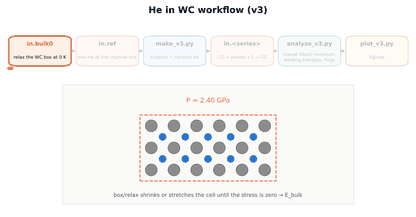

G2_search.gif


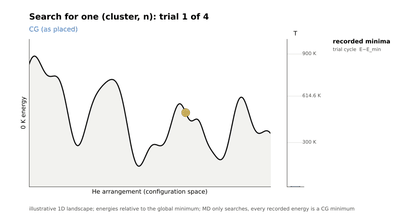

G3_vacancy_filling.gif


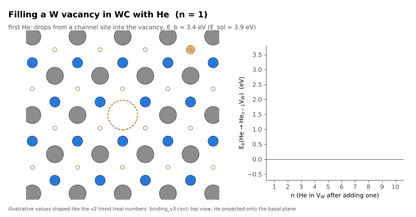

G4_jw_vacancy_rule.gif


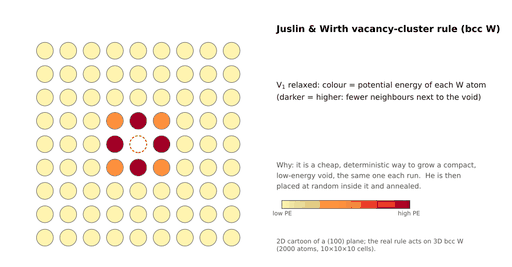

In [10]:
show(os.path.join('..', 'gifs'), ['G1_workflow.gif', 'G2_search.gif', 'G3_vacancy_filling.gif', 'G4_jw_vacancy_rule.gif'], gif_kb=900)